### SVG-Fraktale – Lösung Schritt für Schritt

*31. Bundeswettbewerb Informatik (2012), 1. Runde, Aufgabe 4*

Ein Fraktal ist eine selbstähnliche Figur. Es entsteht, indem, ausgehend von einer Grundfigur, geometrische Objekte schrittweise verfeinert werden. Ein bekanntes Fraktal ist zum Beispiel der Sierpinski-Teppich.

Scalable Vector Graphics (SVG) ist eine Sprache, in der sich geometrische Objekte mit leicht lesbaren Sprachelementen beschreiben lassen, um sie z. B. in Webbrowsern anzuzeigen. Für eine Lösung dieser Aufgabe genügen der „SVG-Rahmen“

```xml
<?xml version="1.0"?>
<svg xmlns="http://www.w3.org/2000/svg"> elemente </svg>
```

und die Elemente `rect` (`x`, `y`, `width`, `height`, `fill`), `circle` und `line` (`x1`, `y1`, `x2`, `y2`, `stroke`, `stroke-width`).

Die Grundfigur (erste Stufe) des Sierpinski-Teppichs ist ein weißes Quadrat. Ein Verfeinerungsschritt ersetzt jedes weiße Quadrat durch neun kleinere, gleich große Quadrate, von denen das mittlere schwarz und alle anderen weiß sind. Die zweite Stufe besteht also aus neun Quadraten der Seitenlänge 60 (das mittlere schwarz).

#### Aufgabe 4

Wähle eine der bereitgestellten Grundfiguren oder denke dir selbst eine aus. Schreibe ein Programm, das die Grundfigur oder eine bereits berechnete Verfeinerungsstufe aus einer SVG-Datei einliest und eine neue SVG-Datei erzeugt, die die nächste Stufe beschreibt. Die SVG-Dateien sollen von gängigen Web-Browsern angezeigt werden können. Es genügt, wenn eine Ausführung des Programms nur einen Verfeinerungsschritt vornimmt.

**Zu den Daten:** Fünf Grundfiguren: `figur0_beispiel.svg` (weißes Quadrat, Sierpinski-Teppich), `figur1_linie.svg` (Linie, Koch-Kurve), `figur2_u-form.svg` (U aus drei Linien, Hilbert-Kurve), `figur3_dreieck.svg` (Dreieck aus drei Linien, Koch-Flocke) und `figur4_dreieck-polygon.svg` (schwarzes Dreieck als `polygon`, Sierpinski-Dreieck). Die Zuordnung stammt aus den Lösungshinweisen. Wir lösen **alle fünf**; verlangt ist nur eines. In `eigene_testdaten/` liegen zwei weitere Figuren.

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**
- **Ersetzungsregel (Verfeinerung):** Bei vier der fünf Fraktale reicht es, jedes Element der Figur **einzeln** durch eine Handvoll neuer Elemente zu ersetzen. Man braucht keinen Blick auf die ganze Figur.
- **Ganze Figur kopieren (Hilbert-Kurve):** Hier wird die komplette Figur viermal verkleinert, gedreht und verschoben eingesetzt und mit drei neuen Linien verbunden.
- **Vektorrechnung mit Punkten:** Drittelpunkte einer Strecke und die Drehung eines Punktes um 60 Grad um einen anderen Punkt.
- **Umlaufsinn eines Vielecks:** Aus dem Vorzeichen einer Summe erkennt man, ob die Linien einer Figur im oder gegen den Uhrzeigersinn laufen. Das brauchen wir, damit die Koch-Flocke ihre Zacken **nach außen** bildet.
- **Kommazahlen:** Nach dem Teilen durch 3 passen die Koordinaten nicht mehr in ganze Zahlen. Deshalb rechnen wir mit `float`.

**Nützliche Bibliotheken**
- `xml.etree.ElementTree`: liest XML (also auch SVG) ein, egal ob ein Element in einer Zeile steht oder über mehrere Zeilen verteilt ist.
- `math.sin`, `math.cos`, `math.radians` für die 60-Grad-Drehung.
- `matplotlib.pyplot`: zeichnet die Figuren, damit wir sie hier im Notebook sehen (der Browser zeigt die SVG-Datei selbst an).

## Die Idee in Worten

**Eine Figur ist eine Liste von Elementen.** Jedes Element merken wir uns als kleines Wörterbuch, z. B. `{'art': 'rect', 'x': 0, 'y': 0, 'breite': 180, 'hoehe': 180, 'fill': 'white'}`. Das Programm hat drei Teile:

1. **Einlesen:** SVG-Datei → Liste von Elementen.
2. **Verfeinern:** Liste → neue Liste (hier steckt das Fraktal).
3. **Schreiben:** Liste → SVG-Text.

**Die fünf Regeln.**

| Fraktal | Grundfigur | Ersetzung |
|---|---|---|
| Sierpinski-Teppich | weißes Quadrat | weißes Quadrat → 9 Quadrate mit Seite/3, das mittlere schwarz; schwarze Quadrate bleiben |
| Sierpinski-Dreieck | schwarzes Dreieck | schwarzes Dreieck → 3 schwarze Eckdreiecke und ein weißes Mittendreieck (aus den Seitenmitten); weiße bleiben |
| Koch-Kurve | Linie | Linie → 4 Linien: Drittel, zwei Seiten eines gleichseitigen Dreiecks über dem mittleren Drittel, Drittel |
| Koch-Flocke | Dreieck aus Linien | wie Koch-Kurve, aber die Zacke zeigt nach **außen** |
| Hilbert-Kurve | U aus 3 Linien | die ganze Kurve 4 Mal verkleinert (zwei davon gedreht), verbunden durch 3 neue Linien |

**Zur Zacke der Koch-Kurve.** Sei die Linie von `A` nach `B`, `P1` der erste und `P2` der zweite Drittelpunkt. Die Spitze `S` ist `P2`, um 60 Grad um `P1` gedreht. Das Vorzeichen des Winkels entscheidet, auf welcher Seite die Zacke liegt.

**Zum Hilbert-Quadrat.** Die U-Form hat Start und Ende an der oberen Seite ihres Quadrats. Die neue Kurve soll **dasselbe** Quadrat füllen. Die vier Kopien werden verkleinert, dazwischen bleibt Platz für die drei Verbindungslinien. Damit am Ende alle Linien gleich lang sind (wie es sein muss), rechnen wir den Verkleinerungsfaktor `c` aus der Anzahl der Linien aus (siehe Schritt 4).

## Schritt 1: SVG einlesen und schreiben

`ET.parse(dateiname)` liest die Datei, `getroot()` ist das `svg`-Element, darunter hängen die Zeichenelemente. Der Tagname enthält den Namensraum (`{http://www.w3.org/2000/svg}rect`), den schneiden wir ab. Ein `polygon` hat statt Zahlen eine Zeichenkette `points="100,200 200,200 150,113.39746"`, die wir in eine Liste von Punkten zerlegen.

Was wir nicht kennen (z. B. `circle`), übernehmen wir unverändert in die Ausgabe. Beim Schreiben bauen wir den Text selbst zusammen.

In [ ]:
import xml.etree.ElementTree as ET
import math


def lies_element(knoten):
    """Macht aus einem XML-Knoten ein Wörterbuch (oder None, wenn wir es nicht kennen)."""
    art = knoten.tag.split('}')[-1]            # Namensraum abschneiden
    a = knoten.attrib
    if art == 'rect':
        return {'art': 'rect', 'x': float(a['x']), 'y': float(a['y']),
                'breite': float(a['width']), 'hoehe': float(a['height']), 'fill': a['fill']}
    if art == 'line':
        return {'art': 'line', 'p1': (float(a['x1']), float(a['y1'])), 'p2': (float(a['x2']), float(a['y2'])),
                'stroke': a.get('stroke', 'black'), 'breite': a.get('stroke-width', '1')}
    if art == 'polygon':
        punkte = []
        for paar in a['points'].replace(',', ' ').split():
            punkte.append(float(paar))
        punkte = [(punkte[i], punkte[i + 1]) for i in range(0, len(punkte), 2)]
        return {'art': 'polygon', 'punkte': punkte, 'fill': a['fill']}
    return None


def lies_svg(wurzel):
    """Liest alle Zeichenelemente; unbekannte Elemente werden mit ihrem XML-Text als 'roh' mitgeführt."""
    figur = []
    for knoten in wurzel:
        element = lies_element(knoten)
        if element is None:
            element = {'art': 'roh', 'text': ET.tostring(knoten, encoding='unicode').strip()}
        figur.append(element)
    return figur


def lies_datei(dateiname):
    return lies_svg(ET.parse(dateiname).getroot())


def z(zahl):
    """Zahl für die SVG-Datei: auf 5 Stellen gerundet, 100.0 statt -0.0."""
    return str(round(zahl, 5) + 0.0)


def schreibe_element(e):
    if e['art'] == 'rect':
        return ('<rect x="%s" y="%s" width="%s" height="%s" fill="%s"/>' % (z(e['x']), z(e['y']), z(e['breite']), z(e['hoehe']), e['fill']))
    if e['art'] == 'line':
        return ('<line x1="%s" y1="%s" x2="%s" y2="%s" stroke="%s" stroke-width="%s"/>' % (z(e['p1'][0]), z(e['p1'][1]), z(e['p2'][0]), z(e['p2'][1]), e['stroke'], e['breite']))
    if e['art'] == 'polygon':
        punkte = ' '.join(z(x) + ',' + z(y) for x, y in e['punkte'])
        return '<polygon points="%s" fill="%s"/>' % (punkte, e['fill'])
    return e['text']


def schreibe_svg(figur):
    zeilen = ['<?xml version="1.0"?>', '<svg xmlns="http://www.w3.org/2000/svg">']
    for e in figur:
        zeilen.append('  ' + schreibe_element(e))
    zeilen.append('</svg>')
    return '\n'.join(zeilen) + '\n'


for name in ['figur0_beispiel', 'figur1_linie', 'figur2_u-form', 'figur3_dreieck', 'figur4_dreieck-polygon']:
    figur = lies_datei('beispieldaten/' + name + '.svg')
    print(name, '->', len(figur), 'Element(e), erstes:', figur[0]['art'])
print()
print(schreibe_svg(lies_datei('beispieldaten/figur4_dreieck-polygon.svg')))

figur0_beispiel -> 1 Element(e), erstes: rect
figur1_linie -> 1 Element(e), erstes: line
figur2_u-form -> 3 Element(e), erstes: line
figur3_dreieck -> 3 Element(e), erstes: line
figur4_dreieck-polygon -> 1 Element(e), erstes: polygon

<?xml version="1.0"?>
<svg xmlns="http://www.w3.org/2000/svg">
  <polygon points="100.0,200.0 200.0,200.0 150.0,113.39746" fill="black"/>
</svg>



Das Einlesen und Schreiben funktioniert. Eine kleine Probe: Was wir schreiben, muss sich wieder einlesen lassen und dieselbe Figur ergeben. Das prüfen wir am Ende mit `assert`, ebenso, dass die Elemente nicht auf einer Zeile stehen müssen (siehe die eigene Testdatei weiter unten).

## Schritt 2: Sierpinski-Teppich und Sierpinski-Dreieck

**Teppich.** Ist das Quadrat weiß, ersetzen wir es durch neun Quadrate der Seitenlänge `s = breite / 3`. Wir gehen zeilenweise durch das 3 × 3-Raster, nur das mittlere Feld (`zeile == 1` und `spalte == 1`) ist schwarz. Alles andere geben wir unverändert aus.

**Dreieck.** Ein schwarzes Dreieck `A B C` hat die Seitenmitten `mAB`, `mAC`, `mBC`. Daraus entstehen drei schwarze Eckdreiecke `A mAB mAC`, `B mAB mBC`, `C mAC mBC` und das weiße Dreieck `mAB mAC mBC`. Weiße Dreiecke bleiben (genau umgekehrt zum Teppich: dort bleibt das schwarze Quadrat).

In [ ]:
def mitte(p, q):
    return ((p[0] + q[0]) / 2, (p[1] + q[1]) / 2)


def teppich(figur):
    neu = []
    for e in figur:
        if e['art'] == 'rect' and e['fill'] == 'white':
            s = e['breite'] / 3
            t = e['hoehe'] / 3
            for zeile in range(3):
                for spalte in range(3):
                    farbe = 'white'
                    if zeile == 1 and spalte == 1:
                        farbe = 'black'
                    neu.append({'art': 'rect', 'x': e['x'] + spalte * s, 'y': e['y'] + zeile * t,
                                'breite': s, 'hoehe': t, 'fill': farbe})
        else:
            neu.append(e)
    return neu


def sierpinski_dreieck(figur):
    neu = []
    for e in figur:
        if e['art'] == 'polygon' and e['fill'] == 'black' and len(e['punkte']) == 3:
            a, b, c = e['punkte']
            ab, ac, bc = mitte(a, b), mitte(a, c), mitte(b, c)
            neu.append({'art': 'polygon', 'punkte': [a, ab, ac], 'fill': 'black'})
            neu.append({'art': 'polygon', 'punkte': [b, ab, bc], 'fill': 'black'})
            neu.append({'art': 'polygon', 'punkte': [c, ac, bc], 'fill': 'black'})
            neu.append({'art': 'polygon', 'punkte': [ab, ac, bc], 'fill': 'white'})
        else:
            neu.append(e)
    return neu


stufe2 = teppich(lies_datei('beispieldaten/figur0_beispiel.svg'))
print(schreibe_svg(stufe2))

<?xml version="1.0"?>
<svg xmlns="http://www.w3.org/2000/svg">
  <rect x="0.0" y="0.0" width="60.0" height="60.0" fill="white"/>
  <rect x="60.0" y="0.0" width="60.0" height="60.0" fill="white"/>
  <rect x="120.0" y="0.0" width="60.0" height="60.0" fill="white"/>
  <rect x="0.0" y="60.0" width="60.0" height="60.0" fill="white"/>
  <rect x="60.0" y="60.0" width="60.0" height="60.0" fill="black"/>
  <rect x="120.0" y="60.0" width="60.0" height="60.0" fill="white"/>
  <rect x="0.0" y="120.0" width="60.0" height="60.0" fill="white"/>
  <rect x="60.0" y="120.0" width="60.0" height="60.0" fill="white"/>
  <rect x="120.0" y="120.0" width="60.0" height="60.0" fill="white"/>
</svg>



Das ist genau die zweite Stufe aus dem Aufgabentext (neun Quadrate der Seite 60, das mittlere schwarz). Für das Dreieck zeigen wir die zweite Stufe weiter unten im Vergleich mit den Lösungshinweisen.

## Schritt 3: Koch-Kurve und Koch-Flocke

Für eine Linie von `A` nach `B` ist `d = B − A`. Dann ist `P1 = A + d/3`, `P2 = A + 2d/3` und die Spitze `S = P1 + dreh(P2 − P1, Winkel)`. Die Drehung eines Vektors `(vx, vy)` um den Winkel `w` ist

`(vx·cos w − vy·sin w, vx·sin w + vy·cos w)`.

Mit `w = −60°` zeigt die Zacke bei einer Linie von links nach rechts nach **oben** (in der SVG-Welt wächst `y` nach unten, oben heißt kleineres `y`). Das ist die Koch-Kurve der Hinweise. Mit `w = +60°` zeigt sie nach unten.

**Wie weiß die Flocke, wo „außen“ ist?** Die Dreieckslinien der Grundfigur laufen in einem festen Umlaufsinn. Wir bilden für jede Linie `x1·y2 − x2·y1` und summieren alles. Ist die Summe negativ (so wie bei `figur3_dreieck.svg`), muss die Zacke mit `+60°` gebildet werden, ist sie positiv, mit `−60°`. Das gilt für **jedes** geschlossene Vieleck und bleibt nach jedem Verfeinern gleich, denn die Zacken liegen außen.

Kurve und Flocke unterscheiden sich im Programm nur im Winkel. Für die Kurve geben wir den Winkel fest vor, für die Flocke bestimmen wir ihn aus der Figur.

In [ ]:
def koch_ersetze(figur, winkel):
    """Ersetzt jede Linie durch vier Linien mit Zacke (winkel in Grad, -60: nach oben, +60: nach unten bei Links-nach-rechts)."""
    c = math.cos(math.radians(winkel))
    s = math.sin(math.radians(winkel))
    neu = []
    for e in figur:
        if e['art'] != 'line':
            neu.append(e)
            continue
        a, b = e['p1'], e['p2']
        dx, dy = (b[0] - a[0]) / 3, (b[1] - a[1]) / 3
        p1 = (a[0] + dx, a[1] + dy)
        p2 = (a[0] + 2 * dx, a[1] + 2 * dy)
        spitze = (p1[0] + dx * c - dy * s, p1[1] + dx * s + dy * c)
        for start, ende in [(a, p1), (p1, spitze), (spitze, p2), (p2, b)]:
            neu.append({'art': 'line', 'p1': start, 'p2': ende, 'stroke': e['stroke'], 'breite': e['breite']})
    return neu


def koch_kurve(figur):
    return koch_ersetze(figur, -60)


def umlauf(figur):
    """Summe von x1*y2 - x2*y1 über alle Linien: negativ oder positiv je nach Umlaufsinn."""
    summe = 0
    for e in figur:
        if e['art'] == 'line':
            summe += e['p1'][0] * e['p2'][1] - e['p2'][0] * e['p1'][1]
    return summe


def koch_flocke(figur):
    if umlauf(figur) < 0:
        return koch_ersetze(figur, +60)
    return koch_ersetze(figur, -60)


dreieck = lies_datei('beispieldaten/figur3_dreieck.svg')
print('Umlauf von figur3_dreieck:', round(umlauf(dreieck), 1), '-> Zacken mit +60 Grad')
print('Umlauf von figur2_u-form (nur zum Vergleich):', round(umlauf(lies_datei('beispieldaten/figur2_u-form.svg')), 1))
print()
print(schreibe_svg(koch_kurve(lies_datei('beispieldaten/figur1_linie.svg'))))

Umlauf von figur3_dreieck: -8660.3 -> Zacken mit +60 Grad
Umlauf von figur2_u-form (nur zum Vergleich): -30000.0

<?xml version="1.0"?>
<svg xmlns="http://www.w3.org/2000/svg">
  <line x1="100.0" y1="100.0" x2="133.33333" y2="100.0" stroke="black" stroke-width="1"/>
  <line x1="133.33333" y1="100.0" x2="150.0" y2="71.13249" stroke="black" stroke-width="1"/>
  <line x1="150.0" y1="71.13249" x2="166.66667" y2="100.0" stroke="black" stroke-width="1"/>
  <line x1="166.66667" y1="100.0" x2="200.0" y2="100.0" stroke="black" stroke-width="1"/>
</svg>



## Schritt 4: Hilbert-Kurve

Hier brauchen wir die ganze Figur. Das Quadrat der Kurve ist ihr **Begrenzungsrechteck**: kleinstes und größtes `x` und `y` aller Endpunkte, bei `figur2_u-form.svg` also `100 … 200` in beide Richtungen. Wir rechnen jeden Punkt in **Einheitskoordinaten** `(u, v)` mit `0 ≤ u, v ≤ 1` um (`u = (x − x0) / breite`). Start der Kurve ist `(0, 0)` (oben links), Ende `(1, 0)` (oben rechts).

**Verkleinerungsfaktor.** Eine Hilbert-Kurve mit `L` Linien (alle gleich lang) hat `k = √(L+1) − 1` Linien pro Seite des Quadrats (bei der U-Form: `L = 3`, `k = 1`). Die vier Kopien haben zusammen mit einer Verbindungslinie dazwischen die Breite `2c + c/k` (die Verbindungslinie ist so lang wie eine Linie der Kopie, also `c/k`). Das soll genau die Breite 1 des Quadrats sein, also ist `c = k / (2k + 1)`. Für die U-Form ist `c = 1/3`, bei der nächsten Stufe (`k = 3`) `c = 3/7`.

Die vier Kopien (jeweils um den Faktor `c` verkleinert):

| Kopie | Lage | Abbildung `(u, v) →` | Start → Ende der Kopie |
|---|---|---|---|
| 1 | oben links, um 90° nach links gedreht | `(c·v, c·u)` | `(0, 0)` → `(0, c)` |
| 2 | unten links, nicht gedreht | `(c·u, 1−c + c·v)` | `(0, 1−c)` → `(c, 1−c)` |
| 3 | unten rechts, nicht gedreht | `(1−c + c·u, 1−c + c·v)` | `(1−c, 1−c)` → `(1, 1−c)` |
| 4 | oben rechts, um 90° nach rechts gedreht | `(1 − c·v, c − c·u)` | `(1, c)` → `(1, 0)` |

(Die Abbildungen für Kopie 1 und 4 sind Spiegelungen an einer Diagonale. Weil die Hilbert-Kurve links-rechts-symmetrisch ist, ergibt das dieselben Linien wie die Drehung aus den Hinweisen, nur mit richtig herum laufendem Start und Ende. Wir prüfen es unten an den Linien.)

Das Ende jeder Kopie fällt nicht auf den Start der nächsten, dazwischen liegt eine Lücke: `(0, c) → (0, 1−c)`, `(c, 1−c) → (1−c, 1−c)` und `(1, 1−c) → (1, c)`. Genau diese drei Linien kommen neu hinzu.

Annahme (wie in den Hinweisen): Die Grundfigur ist ein Quadrat, Start und Ende liegen oben.

In [ ]:
def hilbert(figur):
    linien = [e for e in figur if e['art'] == 'line']
    andere = [e for e in figur if e['art'] != 'line']
    xs = [p[0] for e in linien for p in (e['p1'], e['p2'])]
    ys = [p[1] for e in linien for p in (e['p1'], e['p2'])]
    x0, y0 = min(xs), min(ys)
    breite, hoehe = max(xs) - x0, max(ys) - y0

    k = math.sqrt(len(linien) + 1) - 1          # Linien pro Seite des Quadrats
    c = k / (2 * k + 1)                         # Verkleinerungsfaktor der Kopien

    def abbildungen():
        # jede Abbildung rechnet Einheitskoordinaten (u, v) in neue Einheitskoordinaten um
        return [lambda u, v: (c * v, c * u),
                lambda u, v: (c * u, 1 - c + c * v),
                lambda u, v: (1 - c + c * u, 1 - c + c * v),
                lambda u, v: (1 - c * v, c - c * u)]

    def punkt(uv):
        return (x0 + uv[0] * breite, y0 + uv[1] * hoehe)

    vorlage = linien[0]
    neu = list(andere)
    for abbildung in abbildungen():
        for e in linien:
            u1, v1 = (e['p1'][0] - x0) / breite, (e['p1'][1] - y0) / hoehe
            u2, v2 = (e['p2'][0] - x0) / breite, (e['p2'][1] - y0) / hoehe
            neu.append({'art': 'line', 'p1': punkt(abbildung(u1, v1)), 'p2': punkt(abbildung(u2, v2)),
                        'stroke': e['stroke'], 'breite': e['breite']})
    for start, ende in [((0, c), (0, 1 - c)), ((c, 1 - c), (1 - c, 1 - c)), ((1, 1 - c), (1, c))]:
        neu.append({'art': 'line', 'p1': punkt(start), 'p2': punkt(ende),
                    'stroke': vorlage['stroke'], 'breite': vorlage['breite']})
    return neu


u_form = lies_datei('beispieldaten/figur2_u-form.svg')
stufe2_hilbert = hilbert(u_form)
print('Linien:', len(u_form), '->', len(stufe2_hilbert))
for e in stufe2_hilbert[:5]:
    print(schreibe_element(e))
print('...')

Linien: 3 -> 15
<line x1="100.0" y1="100.0" x2="133.33333" y2="100.0" stroke="black" stroke-width="1"/>
<line x1="133.33333" y1="100.0" x2="133.33333" y2="133.33333" stroke="black" stroke-width="1"/>
<line x1="133.33333" y1="133.33333" x2="100.0" y2="133.33333" stroke="black" stroke-width="1"/>
<line x1="100.0" y1="166.66667" x2="100.0" y2="200.0" stroke="black" stroke-width="1"/>
<line x1="100.0" y1="200.0" x2="133.33333" y2="200.0" stroke="black" stroke-width="1"/>
...


Das sind 4 · 3 + 3 = 15 Linien. Gleich sehen wir die Figur.

## Schritt 5: Alles zusammen und zeichnen

`verfeinere(figur, art)` wählt die Regel nach dem Namen. Zum Ansehen zeichnen wir die Stufen 1 bis 4 jedes Fraktals mit `matplotlib` (der Browser würde die SVG-Dateien ebenso anzeigen). Mehrfaches Verfeinern ist einfach eine Schleife.

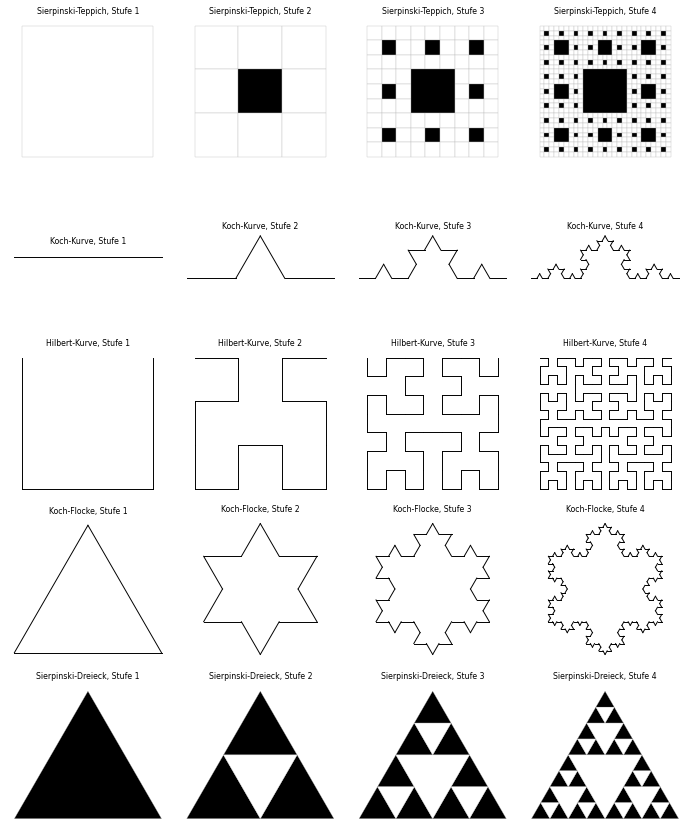

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon

REGELN = {'teppich': teppich, 'dreieck': sierpinski_dreieck, 'kurve': koch_kurve, 'flocke': koch_flocke, 'hilbert': hilbert}


def verfeinere(figur, art):
    if art not in REGELN:
        raise ValueError('unbekanntes Fraktal: ' + art)
    if art == 'teppich':
        return teppich(figur)
    if art == 'dreieck':
        return sierpinski_dreieck(figur)
    if art == 'kurve':
        return koch_kurve(figur)
    if art == 'flocke':
        return koch_flocke(figur)
    return hilbert(figur)


def stufen(figur, art, anzahl):
    """Stufe 1 (= Grundfigur) bis Stufe anzahl."""
    alle = [figur]
    for _ in range(anzahl - 1):
        alle.append(verfeinere(alle[-1], art))
    return alle


def zeichne(achse, figur):
    for e in figur:
        if e['art'] == 'rect':
            achse.add_patch(Rectangle((e['x'], e['y']), e['breite'], e['hoehe'], facecolor=e['fill'],
                                      edgecolor='#aaaaaa', linewidth=0.3))
        elif e['art'] == 'polygon':
            achse.add_patch(Polygon(e['punkte'], closed=True, facecolor=e['fill'], edgecolor='#aaaaaa', linewidth=0.3))
        elif e['art'] == 'line':
            achse.plot([e['p1'][0], e['p2'][0]], [e['p1'][1], e['p2'][1]], color=e['stroke'], linewidth=1)
    achse.autoscale_view()
    achse.set_aspect('equal')
    achse.invert_yaxis()            # SVG: y wächst nach unten
    achse.axis('off')


FRAKTALE = [('Sierpinski-Teppich', 'figur0_beispiel', 'teppich'), ('Koch-Kurve', 'figur1_linie', 'kurve'),
            ('Hilbert-Kurve', 'figur2_u-form', 'hilbert'), ('Koch-Flocke', 'figur3_dreieck', 'flocke'),
            ('Sierpinski-Dreieck', 'figur4_dreieck-polygon', 'dreieck')]
alle_stufen = {}
bild, achsen = plt.subplots(5, 4, figsize=(10, 12))
for reihe, (titel, datei, art) in enumerate(FRAKTALE):
    alle_stufen[art] = stufen(lies_datei('beispieldaten/' + datei + '.svg'), art, 4)
    for spalte in range(4):
        zeichne(achsen[reihe][spalte], alle_stufen[art][spalte])
        achsen[reihe][spalte].set_title('%s, Stufe %d' % (titel, spalte + 1), fontsize=8)
plt.tight_layout()
plt.show()

Alle fünf Fraktale entstehen wie erwartet. Wie viele Elemente (und damit wie lang die SVG-Datei) werden es? Das wächst schnell:

In [ ]:
print('Anzahl Elemente je Stufe 1 bis 6:')
for titel, datei, art in FRAKTALE:
    figur = lies_datei('beispieldaten/' + datei + '.svg')
    anzahlen = [len(figur)]
    for _ in range(5):
        figur = verfeinere(figur, art)
        anzahlen.append(len(figur))
    print('%-20s' % titel, anzahlen)

Anzahl Elemente je Stufe 1 bis 6:
Sierpinski-Teppich   [1, 9, 73, 585, 4681, 37449]
Koch-Kurve           [1, 4, 16, 64, 256, 1024]
Hilbert-Kurve        [3, 15, 63, 255, 1023, 4095]
Koch-Flocke          [3, 12, 48, 192, 768, 3072]
Sierpinski-Dreieck   [1, 4, 13, 40, 121, 364]


Der Teppich wächst mit 8 neuen weißen Quadraten je weißem Quadrat (`1, 9, 73, 585, …`), das Dreieck mit dem Faktor 3 (`1, 4, 13, 40, …`), die Kurve mit dem Faktor 4 (`1, 4, 16, …`), die Flocke ebenso (`3, 12, 48, …`), die Hilbert-Kurve als `4^n − 1` Linien (`3, 15, 63, …`). Ab etwa Stufe 7 bis 8 haben die Elemente nur noch Bruchteile eines Pixels. Deshalb darf ein Programm laut Hinweisen bei kleinen Abständen aufhören, Elemente weiter zu zerlegen.

## Schritt 6: Vergleich mit den Lösungshinweisen

Die Hinweise drucken die zweiten Stufen von Sierpinski-Dreieck, Koch-Kurve und Koch-Flocke ab (auf fünf Nachkommastellen gerundet, mit kleinen Rundungsunterschieden in der letzten Stelle). Wir vergleichen **Punkt für Punkt** mit einer Toleranz von `0.001`. Auch die Reihenfolge der Elemente stimmt überein.

In [ ]:
def punkte_von(figur):
    """Alle Punkte einer Figur in der Reihenfolge der Elemente (Polygone: alle Ecken, Linien: Anfang und Ende)."""
    liste = []
    for e in figur:
        if e['art'] == 'polygon':
            liste.extend(e['punkte'])
        if e['art'] == 'line':
            liste.extend([e['p1'], e['p2']])
    return liste


def gleich(figur, erwartet, farben=None):
    mein = punkte_von(figur)
    if len(mein) != len(erwartet):
        return False
    for (x, y), (ex, ey) in zip(mein, erwartet):
        if abs(x - ex) > 0.001 or abs(y - ey) > 0.001:
            return False
    return True


# aus den Hinweisen: Ausgabedateien der zweiten Stufe
hinweis_dreieck = [(100, 200), (150, 200), (125, 156.69873), (200, 200), (150, 200), (175, 156.69873),
                   (150, 113.39746), (125, 156.69873), (175, 156.69873), (150, 200), (125, 156.69873), (175, 156.69873)]
hinweis_kurve = [(100, 100), (133.33333, 100), (133.33333, 100), (150, 71.13249), (150, 71.13249), (166.66666, 100),
                 (166.66666, 100), (200, 100)]
flocke_ecken = [(100, 200), (133.33333, 200), (150, 228.86751), (166.66666, 200), (200, 200), (183.33333, 171.13249),
                (200.00002, 142.26498), (166.66667, 142.26497), (150, 113.39746), (133.33333, 142.26497),
                (99.99999, 142.26498), (116.66667, 171.13249), (100, 200)]
hinweis_flocke = []
for i in range(12):
    hinweis_flocke.extend([flocke_ecken[i], flocke_ecken[i + 1]])

pruefung_dreieck = gleich(alle_stufen['dreieck'][1], hinweis_dreieck)
pruefung_kurve = gleich(alle_stufen['kurve'][1], hinweis_kurve)
pruefung_flocke = gleich(alle_stufen['flocke'][1], hinweis_flocke)
print('Sierpinski-Dreieck, Stufe 2 wie in den Hinweisen:', pruefung_dreieck)
print('Koch-Kurve, Stufe 2 wie in den Hinweisen:       ', pruefung_kurve)
print('Koch-Flocke, Stufe 2 wie in den Hinweisen:      ', pruefung_flocke)

Sierpinski-Dreieck, Stufe 2 wie in den Hinweisen: True
Koch-Kurve, Stufe 2 wie in den Hinweisen:        True
Koch-Flocke, Stufe 2 wie in den Hinweisen:       True


Der Teppich (Stufe 2) ist die Datei aus dem Aufgabentext, die wir oben schon gesehen haben. Für die Hilbert-Kurve druckt das Aufgabenblatt keine Datei, deshalb prüfen wir sie über Eigenschaften, die eine Hilbert-Kurve haben **muss**. Wir tun das nicht nur für Stufe 2, sondern bis Stufe 6:
- Es gibt `4^n − 1` Linien, alle gleich lang (`100 / (2^n − 1)`).
- Die Linien bilden **einen** durchgehenden Weg: Jede Linie beginnt dort, wo eine andere endet, nur Start und Ende des Wegs nicht.
- Der Weg besucht `4^n` verschiedene Punkte auf einem Raster, alle im Quadrat von 100 bis 200.
- Start und Ende liegen oben links und oben rechts.

Für Koch-Kurve und -Flocke prüfen wir ebenfalls: Linienanzahl, gleiche Länge `100 / 3^(n−1)`, und die Flocke ist ein **geschlossener** Weg.

In [ ]:
def laenge(e):
    return math.dist(e['p1'], e['p2'])


def ist_weg(figur):
    """Kennzeichen: Gibt es genau einen zusammenhängenden Weg? (Grad der Punkte: nur 2, außer zwei Enden mit Grad 1.)"""
    grad = {}
    for e in figur:
        for p in (e['p1'], e['p2']):
            schluessel = (round(p[0], 3), round(p[1], 3))
            grad[schluessel] = grad.get(schluessel, 0) + 1
    enden = [p for p in grad if grad[p] == 1]
    return grad, enden


hilbert_ok = []
for n in range(1, 7):
    figur = stufen(lies_datei('beispieldaten/figur2_u-form.svg'), 'hilbert', n)[-1]
    grad, enden = ist_weg(figur)
    laengen = [laenge(e) for e in figur]
    schritt = 100 / (2 ** n - 1)
    gut = (len(figur) == 4 ** n - 1
           and all(abs(l - schritt) < 1e-6 for l in laengen)
           and len(grad) == 4 ** n and all(g <= 2 for g in grad.values())
           and sorted(enden) == [(100.0, 100.0), (200.0, 100.0)]
           and all(100 - 1e-6 <= x <= 200 + 1e-6 and 100 - 1e-6 <= y <= 200 + 1e-6 for (x, y) in grad))
    hilbert_ok.append(gut)
    print('Hilbert Stufe %d: %5d Linien, Länge je %.4f, %5d Punkte, Enden %s -> %s' % (
        n, len(figur), schritt, len(grad), sorted(enden), gut))

Hilbert Stufe 1:     3 Linien, Länge je 100.0000,     4 Punkte, Enden [(100.0, 100.0), (200.0, 100.0)] -> True
Hilbert Stufe 2:    15 Linien, Länge je 33.3333,    16 Punkte, Enden [(100.0, 100.0), (200.0, 100.0)] -> True
Hilbert Stufe 3:    63 Linien, Länge je 14.2857,    64 Punkte, Enden [(100.0, 100.0), (200.0, 100.0)] -> True
Hilbert Stufe 4:   255 Linien, Länge je 6.6667,   256 Punkte, Enden [(100.0, 100.0), (200.0, 100.0)] -> True
Hilbert Stufe 5:  1023 Linien, Länge je 3.2258,  1024 Punkte, Enden [(100.0, 100.0), (200.0, 100.0)] -> True
Hilbert Stufe 6:  4095 Linien, Länge je 1.5873,  4096 Punkte, Enden [(100.0, 100.0), (200.0, 100.0)] -> True


Und für die Koch-Kurve und die Koch-Flocke:

In [ ]:
koch_ok = []
for n in range(1, 7):
    kurve = stufen(lies_datei('beispieldaten/figur1_linie.svg'), 'kurve', n)[-1]
    flocke = stufen(lies_datei('beispieldaten/figur3_dreieck.svg'), 'flocke', n)[-1]
    seite = 100 / 3 ** (n - 1)
    gut_kurve = len(kurve) == 4 ** (n - 1) and all(abs(laenge(e) - seite) < 1e-6 for e in kurve)
    grad_f, enden_f = ist_weg(flocke)
    gut_flocke = (len(flocke) == 3 * 4 ** (n - 1) and all(abs(laenge(e) - seite) < 1e-6 for e in flocke)
                  and enden_f == [] and all(g == 2 for g in grad_f.values()))
    koch_ok.append(gut_kurve and gut_flocke)
    print('Stufe %d: Kurve %5d Linien, Flocke %5d Linien, Länge je %.4f -> %s' % (
        n, len(kurve), len(flocke), seite, gut_kurve and gut_flocke))

Stufe 1: Kurve     1 Linien, Flocke     3 Linien, Länge je 100.0000 -> True
Stufe 2: Kurve     4 Linien, Flocke    12 Linien, Länge je 33.3333 -> True
Stufe 3: Kurve    16 Linien, Flocke    48 Linien, Länge je 11.1111 -> True
Stufe 4: Kurve    64 Linien, Flocke   192 Linien, Länge je 3.7037 -> True
Stufe 5: Kurve   256 Linien, Flocke   768 Linien, Länge je 1.2346 -> True
Stufe 6: Kurve  1024 Linien, Flocke  3072 Linien, Länge je 0.4115 -> True


## Schritt 7: Eigene Testdateien

Zwei Figuren in `eigene_testdaten/`:
- `figur5_schraege_linie.svg`: eine **schräge blaue** Linie der Dicke 2, deren Attribute **über mehrere Zeilen** verteilt sind. Der XML-Parser stört sich nicht daran (anders als ein Programm, das Zeile für Zeile liest). Farbe und Dicke bleiben erhalten.
- `figur6_quadrat_im_uhrzeigersinn.svg`: ein Quadrat aus vier Linien, im Uhrzeigersinn. Die Zacken der Flocke müssen trotzdem nach außen zeigen. Hier ist die Umlaufsumme **positiv**.

Farbe/Dicke gelesen: blue 2
Linien in Stufe 1, 2, 3: [1, 4, 16]
<line x1="116.66667" y1="216.66667" x2="121.13249" y2="142.26497" stroke="blue" stroke-width="2"/>
Umlauf des Quadrats: 20000 (positiv -> Zacken mit -60 Grad)
Linien in Stufe 1 bis 4: [4, 16, 64, 256]


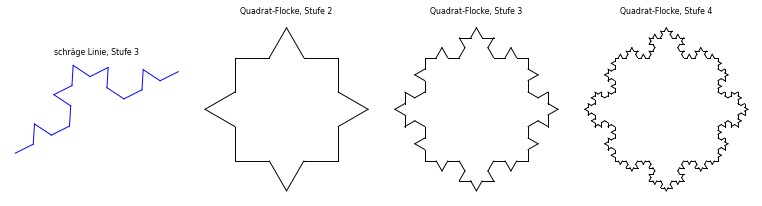

In [ ]:
schraege = lies_datei('eigene_testdaten/figur5_schraege_linie.svg')
print('Farbe/Dicke gelesen:', schraege[0]['stroke'], schraege[0]['breite'])
schraege3 = stufen(schraege, 'kurve', 3)
print('Linien in Stufe 1, 2, 3:', [len(s) for s in schraege3])
print(schreibe_element(schraege3[1][1]))

quadrat = lies_datei('eigene_testdaten/figur6_quadrat_im_uhrzeigersinn.svg')
print('Umlauf des Quadrats:', round(umlauf(quadrat)), '(positiv -> Zacken mit -60 Grad)')
quadrat_stufen = stufen(quadrat, 'flocke', 4)
print('Linien in Stufe 1 bis 4:', [len(s) for s in quadrat_stufen])

bild2, achsen2 = plt.subplots(1, 4, figsize=(11, 3))
zeichne(achsen2[0], schraege3[2])
achsen2[0].set_title('schräge Linie, Stufe 3', fontsize=8)
for i in range(1, 4):
    zeichne(achsen2[i], quadrat_stufen[i])
    achsen2[i].set_title('Quadrat-Flocke, Stufe %d' % (i + 1), fontsize=8)
plt.tight_layout()
plt.show()

Die Quadrat-Flocke wächst nach außen, obwohl die Linien im Uhrzeigersinn laufen. Ohne die Umlaufsumme hätten wir Zacken nach innen bekommen.

**Ein Wort zur Eingabe.** Unser Programm liest SVG mit einem echten XML-Parser. Zeilenumbrüche innerhalb eines Elements, beliebig viele Leerzeichen, `/>` oder `></line>` sind kein Problem. Elemente müssen **nicht** auf einer Zeile stehen. Das ist ein Kriterium der Bewertung. Nicht erlaubt ist, was kein gültiges XML ist. Außerdem rechnen wir nur mit `x`, `y`, `width`, `height`, `points` usw., `transform` oder Maßeinheiten wie `10px` kennt das Programm nicht (dann bricht `float` mit einem Fehler ab).

## Zum Schluss: Mehrfach verfeinern und speichern

Die Aufgabe verlangt eine Datei als Ergebnis. Der Text von `schreibe_svg` gehört in eine Datei, z. B. so (hier nicht ausgeführt, damit das Notebook keine Dateien anlegt):

```python
with open('teppich_stufe3.svg', 'w') as datei:
    datei.write(schreibe_svg(alle_stufen['teppich'][2]))
```

Die Datei öffnest du mit einem Browser. Zur Probe: Der geschriebene Text lässt sich wieder einlesen und ergibt dieselbe Figur (das prüfen die `assert`s im Generator für alle Fraktale, bis Stufe 4).

## Für Neugierige

**Wie groß wird der Teppich wirklich weiß?** In jedem Schritt bleibt von den weißen Flächen 8/9 weiß. Nach `n − 1` Verfeinerungen sind es `(8/9)^(n−1)` der Fläche, das geht gegen null. Stufe 4 hat 512 weiße Quadrate der Seitenlänge 180/27, zusammen 512 · (180/27)² ≈ 22 756 Flächeneinheiten, das sind (8/9)³ der 32 400 des Ausgangsquadrats.

**Abbruch bei kleinen Elementen.** Die Hinweise erlauben, Elemente unter einer Mindestgröße nicht mehr zu zerlegen. Bei `teppich` genügt dazu die Bedingung `e['breite'] > 1` in der `if`-Zeile.

**Andere Rechenwege.** XSLT (das in der Aufgabe erwähnt wird) beschreibt solche Ersetzungen direkt als Regeln pro Element. Die Hilbert-Methode (ganze Figur kopieren) geht auch für Sierpinski-Dreieck (3 Kopien) und Koch-Kurve (4 Kopien, zwei gedreht). MiniZinc haben wir hier nicht verwendet: Es gibt nichts zu suchen oder zu optimieren, jedes Element der nächsten Stufe ist durch eine feste Rechenvorschrift bestimmt.